# Circle (CRCL) valuation with stochastic interest rates and USDC supply

Question: how much is Circle worth when revenue depends on stochastic rates and USDC supply, and which rate path does today's share price imply?

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yfinance as yf
import requests
from scipy import stats, optimize
import statsmodels.api as sm

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams["figure.figsize"] = (10, 4)
rng = np.random.default_rng(42)  # fixed seed so Monte Carlo is reproducible

START_RATES = "2000-01-01"
START_CRCL = "2025-06-01"
CIK_CIRCLE = "0001876042"

## 1. Data collection
### 1.1 CRCL price (yfinance)

[*********************100%***********************]  1 of 1 completed


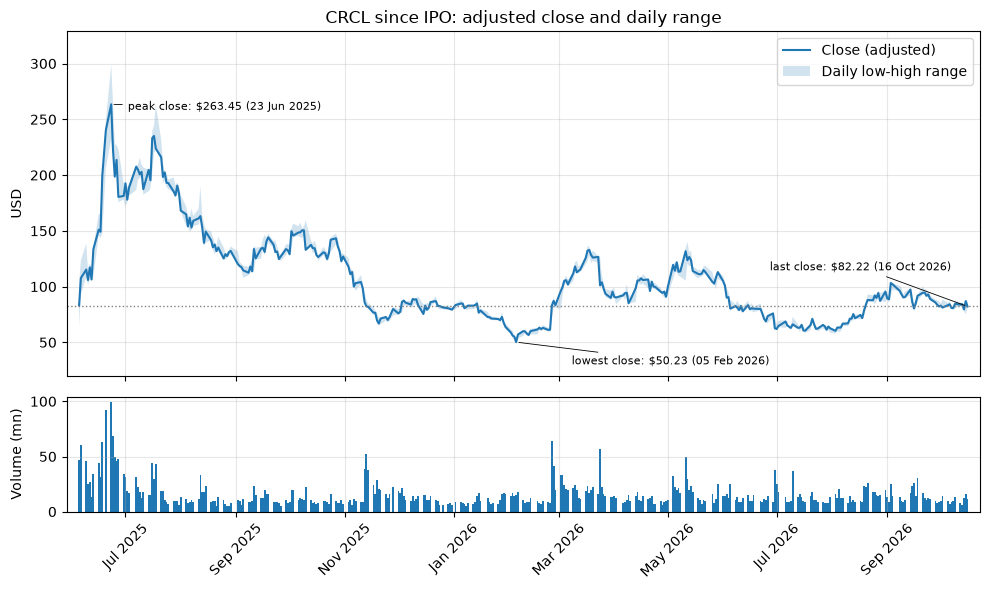

In [2]:
crcl = yf.download("CRCL", start=START_CRCL, auto_adjust=True)
crcl.columns = crcl.columns.droplevel("Ticker")
crcl.columns.name = None

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(crcl.index, crcl["Close"], lw=1.5, label="Close (adjusted)")
ax1.fill_between(crcl.index, crcl["Low"], crcl["High"], alpha=0.2, label="Daily low-high range")
marks = {  # label: (date, text offset in points, horizontal alignment)
    "peak close": (crcl["Close"].idxmax(), (12, -4), "left"),
    "lowest close": (crcl["Close"].idxmin(), (40, -16), "left"),
    "last close": (crcl.index[-1], (-12, 26), "right"),
}
for name, (d, offset, ha) in marks.items():
    ax1.annotate(f"{name}: ${crcl.loc[d, 'Close']:.2f} ({d:%d %b %Y})", xy=(d, crcl.loc[d, "Close"]),
                 xytext=offset, textcoords="offset points", ha=ha, fontsize=8,
                 arrowprops=dict(arrowstyle="-", lw=0.6))
ax1.axhline(crcl["Close"].iloc[-1], ls=":", lw=1, color="gray")  # today's price as reference
ax1.margins(y=0.12)
ax1.set_ylabel("USD")
ax1.set_title("CRCL since IPO: adjusted close and daily range")
ax1.legend(loc="upper right")
ax2.bar(crcl.index, crcl["Volume"] / 1e6, width=1.0)
ax2.set_ylabel("Volume (mn)")
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax2.tick_params(axis="x", labelrotation=45)
ax2.set_xlim(crcl.index[0] - pd.Timedelta(days=7), crcl.index[-1] + pd.Timedelta(days=7))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2 3-month T-bill (FRED DTB3)

,tbill_3m
observation_date,
2026-10-08,4.05
2026-10-09,4.06
2026-10-13,4.09
2026-10-14,4.10
2026-10-15,4.10


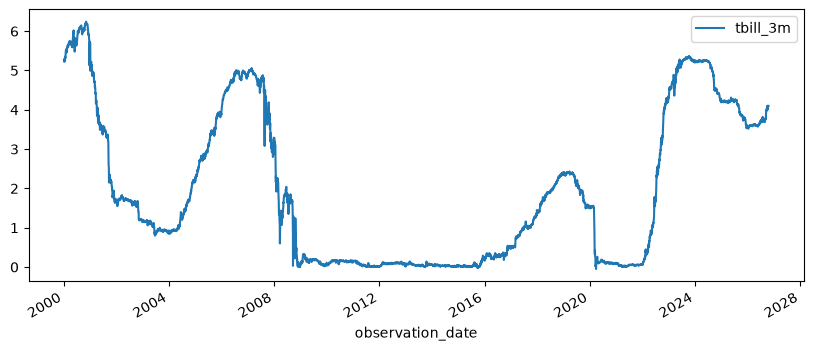

In [3]:
tbill = pd.read_csv(
    "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3",
    index_col=0, parse_dates=True, na_values=".",
).rename(columns={"DTB3": "tbill_3m"})
tbill = tbill.loc[START_RATES:].dropna()
tbill.plot();
tbill.tail()

**Interpretation (T-bill):** The 3-month T-bill rate is 4.10% on 15 Oct 2026. Since 2000 it has moved between very different regimes: annual averages of 5.82% in 2000, 1.01% in 2003, 4.73% in 2006 and 5.07% in 2023. It stayed below 0.25% from March 2009 to December 2015 and from April 2020 to February 2022, about a third of the sample, with a low of -0.05% in March 2020. Reserve income depends on short-term rates: the quarterly average of the T-bill (4.23, 4.10, 3.73, 3.59 and 3.62%) stays within 0.13 pp of the reserve return rate that Circle reports (4.1, 4.2, 3.8, 3.5 and 3.5%), so the T-bill is a reasonable driver for the rate model. Limitation: a Vasicek model allows negative rates and has a single long-run mean, while this sample mixes near-zero and 5% regimes, so the calibrated mean will depend on the window chosen.

### 1.3 USDC supply (DefiLlama, id 2)

In [4]:
url = "https://stablecoins.llama.fi/stablecoincharts/all?stablecoin=2"
raw = requests.get(url, timeout=30)
raw.raise_for_status()
usdc_raw = raw.json()
print(len(usdc_raw))
usdc_raw[0], usdc_raw[-1]

2959


({'date': '1536624000',
  'totalCirculating': {'peggedUSD': 2},
  'totalCirculatingUSD': {'peggedUSD': 2}},
 {'date': '1792195200',
  'totalCirculating': {'peggedUSD': 72749984333.77},
  'totalUnreleased': {'peggedUSD': 1091394176.25},
  'totalCirculatingUSD': {'peggedUSD': 72734876025.59},
  'totalMintedUSD': {'peggedUSD': 0},
  'totalBridgedToUSD': {'peggedUSD': 0}})

,usdc_supply
date,
2026-10-13,"72,860,344,009.00"
2026-10-14,"73,133,116,485.00"
2026-10-15,"72,763,096,585.00"
2026-10-16,"72,828,793,768.00"
2026-10-17,"72,734,876,025.59"


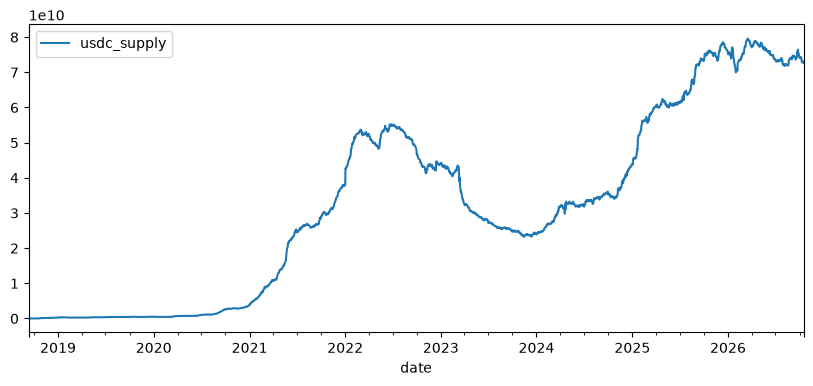

In [5]:
usdc = pd.DataFrame(
    {
        "date": pd.to_datetime([int(x["date"]) for x in usdc_raw], unit="s"),
        "usdc_supply": [x["totalCirculatingUSD"]["peggedUSD"] for x in usdc_raw],
    }
).set_index("date")
usdc.plot();
usdc.tail()

In [6]:
# Quarter-end USDC supply, $ bn. The last row is partial: data runs to 2026-10-17, it is not a quarter end.
(usdc["usdc_supply"].resample("QE").last() / 1e9).round(1).loc["2021":]

date
2021-03-31   10.90
2021-06-30   24.60
2021-09-30   28.70
2021-12-31   38.10
2022-03-31   52.50
2022-06-30   54.90
2022-09-30   47.90
2022-12-31   44.10
2023-03-31   32.60
2023-06-30   27.70
2023-09-30   24.70
2023-12-31   24.00
2024-03-31   31.90
2024-06-30   31.90
2024-09-30   36.00
2024-12-31   43.80
2025-03-31   60.30
2025-06-30   61.30
2025-09-30   73.20
2025-12-31   76.00
2026-03-31   77.40
2026-06-30   73.70
2026-09-30   74.60
2026-12-31   72.70
Freq: QE-DEC, Name: usdc_supply, dtype: float64

**Interpretation (USDC):** USDC supply peaked at $55.2bn on 20 Jun 2022, fell to $23.2bn on 15 Nov 2023 (-58%), reached a high of $79.6bn on 18 Mar 2026 and stands at $72.7bn on 17 Oct 2026. The fall began in mid-2022 and was sharpest around March 2023: supply went from $43.2bn on 8 Mar to $38.0bn on 15 Mar, the week of the SVB failure. Since the start of 2026 it has moved between $70.0bn and $79.6bn. The series has three regimes (growth, decline, recovery) followed by a plateau, so a single growth rate depends on the calibration window.

**SVB / regime decision:** which window calibrates USDC growth is decided in section 3, and the result under other windows is shown as a sensitivity.

### 1.4 Circle quarterly figures (releases, 10-Q/10-K, S-1)
Every hand-entered number cites its source in a comment.

In [7]:
# Circle quarterly figures, $ billions (USDC) and $ millions (income). Q2 2025 to Q2 2026.
# Sources (8-K exhibit 99.1, earnings releases):
#  Q2 2025: sec.gov/Archives/edgar/data/1876042/000162828025039749/q22025epr.htm
#  Q3 2025: sec.gov 8-K 0001876042-25-000045 (release of 2025-11-12; table read from the Business Wire copy)
#  Q4 2025: sec.gov/Archives/edgar/data/1876042/000187604226000032/final_circlereportsfourt.htm
#  Q1 2026: sec.gov/Archives/edgar/data/0001876042/000187604226000148/final_05x11q1epr30.htm
#  Q2 2026: sec.gov/Archives/edgar/data/1876042/000187604226000246/augustepr-circle_q22026f.htm
circle_q = pd.DataFrame(
    {
        "avg_usdc_bn":       [61.0, 67.8, 76.2, 75.2, 76.5],   # Key Operating Indicators
        "end_usdc_bn":       [61.3, 73.7, 75.3, 77.0, 73.3],   # Key Operating Indicators
        "reserve_return_pct":[4.1,  4.2,  3.8,  3.5,  3.5],    # Key Operating Indicators
        "reserve_income":    [634,  711,  733,  653,  668],    # Quarterly Results of Operations
        "total_revenue":     [658,  740,  770,  694,  701],    # idem
        "dist_trans_costs":  [406,  447,  461,  405,  410],    # distribution and transaction costs
        "total_costs":       [407,  448,  461,  407,  412],    # distribution, transaction and other costs
        "rldc":              [251,  292,  309,  287,  289],    # revenue less distribution costs
    },
    index=pd.PeriodIndex(["2025Q2", "2025Q3", "2025Q4", "2026Q1", "2026Q2"], freq="Q"),
)
circle_q

,avg_usdc_bn,end_usdc_bn,reserve_return_pct,reserve_income,total_revenue,dist_trans_costs,total_costs,rldc
2025Q2,61.00,61.30,4.10,634,658,406,407,251
2025Q3,67.80,73.70,4.20,711,740,447,448,292
2025Q4,76.20,75.30,3.80,733,770,461,461,309
2026Q1,75.20,77.00,3.50,653,694,405,407,287
2026Q2,76.50,73.30,3.50,668,701,410,412,289


In [8]:
# Consistency checks on the hand-entered table
assert ((circle_q["total_revenue"] - circle_q["total_costs"] - circle_q["rldc"]).abs() <= 1).all()  # RLDC = revenue - costs (rounding tolerance 1)
implied = circle_q["avg_usdc_bn"] * 1e3 * circle_q["reserve_return_pct"] / 100 / 4  # avg USDC x reserve return / 4, $ mn
(implied - circle_q["reserve_income"]).round(0)

2025Q2   -9.00
2025Q3    1.00
2025Q4   -9.00
2026Q1    5.00
2026Q2    1.00
Freq: Q-DEC, dtype: float64

**Interpretation (Circle table):** The table has five quarters (Q2 2025 to Q2 2026) taken from Circle's earnings releases (8-K). Reserve income is explained by average USDC times the reserve return rate: the implied figure is within $9mn of the reported one in every quarter (under 1.5%), consistent with the return rate being rounded to one decimal. Distribution and transaction costs are 61% to 64% of reserve income (61.4% in Q2 2026), and the RLDC margin is 38% to 41% of total revenue. Average USDC grew from $61.0bn to $76.5bn while the reserve return rate fell from 4.1% to 3.5%, and reserve income stayed between $634mn and $733mn. These two moves happened in the same period, but five points cannot show a relationship between them. Limitation: five quarters allow calibrating margins and the cost share, not estimating a statistical pattern, and the sample covers only a period of falling rates.

### 1.5 Save raw data

In [9]:
crcl.to_csv("../data/crcl_prices.csv")
tbill.to_csv("../data/tbill_3m.csv")
usdc.to_csv("../data/usdc_supply.csv")
circle_q.to_csv("../data/circle_quarterly.csv")

## 2. Unit economics

In [10]:
# TODO

## 3. Calibration (Vasicek via AR(1), GBM for USDC)

In [11]:
# TODO

## 4. Monte Carlo and DCF

In [12]:
# TODO

## 5. Validation against closed form

In [13]:
# TODO

## 6. Implied interest rate

In [14]:
# TODO

## 7. Sensitivity and rate-cut scenario

In [15]:
# TODO

## 8. Conclusions and limitations